# Project: Online Retail Store

## Table of Contents
<ul>
<li><a href="#intro">Introduction</a></li>
<li><a href="#wrangling">Data Wrangling</a></li>
<li><a href="#Questions for Analysis">Questions for Analysis</a></li>
<li><a href="#Data Visualization">Data Visualization</a></li>
<li><a href="#conclusions">Conclusion</a></li>
</ul>

<a id='intro'></a>
## Introduction

### Project Description 
This is a practice analysis framed around the scenario below. It is a portfolio exercise, not work done for an actual client.


An online retail store has needed to review their data and provide insights that would be valuable to the CEO and CMO of the business. The business has been performing well and the management wants to analyze what the major contributing factors are in the revenue so they can strategically plan for next year.

The leadership is interested in viewing the metrics from both an operations and marketing perspective. Management also intends to expand the business and is interested in seeking guidance into areas that are performing well so they can keep a clear focus on what’s working. They would also like to view different metrics based on the demographic information that is available in the data.

Note: Stakeholders don't need "UK" in their analysis




<a id='wrangling'></a>
## Data Wrangling



### General Properties

Let's explore the dataset to know its properties

In [1]:
#Importing the needed packages
import pandas as pd 

In [2]:
#Reading our database
df= pd.read_excel('Online Retail.xlsx')

In [3]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Total,InvoiceDate,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,2010-12-01 08:26:00,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,3.39,20.34,2010-12-01 08:26:00,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,2010-12-01 08:26:00,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,2010-12-01 08:26:00,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,2010-12-01 08:26:00,17850.0,United Kingdom


In [4]:
#Showing the shape of the dastaset
df.shape

(541909, 9)

In [5]:
#Showing some descriptive statistics about the dataset
df.describe()

,Quantity,UnitPrice,Total,InvoiceDate,CustomerID
count,541909.000000,541909.000000,541909.000000,541909,406829.000000
mean,9.552250,4.611114,17.987795,2011-07-04 13:34:57.156386048,15287.690570
min,-80995.000000,-11062.060000,-168469.600000,2010-12-01 08:26:00,12346.000000
25%,1.000000,1.250000,3.400000,2011-03-28 11:34:00,13953.000000
50%,3.000000,2.080000,9.750000,2011-07-19 17:17:00,15152.000000
75%,10.000000,4.130000,17.400000,2011-10-19 11:27:00,16791.000000
max,80995.000000,38970.000000,168469.600000,2011-12-09 12:50:00,18287.000000
std,218.081158,96.759853,378.810824,NaN,1713.600303


In [6]:
#Showing info about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   UnitPrice    541909 non-null  float64       
 5   Total        541909 non-null  float64       
 6   InvoiceDate  541909 non-null  datetime64[ns]
 7   CustomerID   406829 non-null  float64       
 8   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(3), int64(1), object(4)
memory usage: 37.2+ MB


In [7]:
#Count NULL values in the columns
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
UnitPrice           0
Total               0
InvoiceDate         0
CustomerID     135080
Country             0
dtype: int64

In [8]:
#Count the duplicated rows
df.duplicated().sum()

np.int64(5268)

### Data Cleaning
Cleaning choices, and why:

- Exact duplicate rows are dropped.
- Cancellations (invoice numbers starting with "C") and rows with a negative quantity are returns or stock adjustments, not sales, so they are excluded from the sales analysis. They are counted below so the effect is visible.
- Rows with a unit price of 0 or less are excluded (stock adjustments, not priced sales).
- Sales of a single unit are real sales and stay in.
- Rows without a CustomerID stay in. Revenue and product questions do not need the customer.
- All amounts are in pounds (GBP), since this is a UK-based retailer's data.

In [9]:
#Dropping exact duplicates
df = df.drop_duplicates()
print('rows after dropping duplicates:', len(df))

rows after dropping duplicates: 536641


In [10]:
#CustomerID is an identifier, not a number to calculate with
df['CustomerID'] = df['CustomerID'].astype('Int64').astype(str)
is_cancel = df['InvoiceNo'].astype(str).str.startswith('C')
print('cancellation invoices:', is_cancel.sum())
print('negative quantities:', (df['Quantity'] < 0).sum())
print('unit price <= 0:', (df['UnitPrice'] <= 0).sum())

cancellation invoices: 9251
negative quantities: 10587
unit price <= 0: 2512


In [11]:
#Keep real sales only: not cancelled, positive quantity, positive price
sales = df[~is_cancel & (df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()
sales['Month'] = sales['InvoiceDate'].dt.to_period('M')
print('rows kept:', len(sales), 'of', len(df))
print('total revenue (GBP):', round(sales['Total'].sum()))
sales.describe()

rows kept: 524878 of 536641
total revenue (GBP): 10642111


,Quantity,UnitPrice,Total,InvoiceDate
count,524878.000000,524878.000000,524878.000000,524878
mean,10.616600,3.922573,20.275399,2011-07-04 15:30:16.317049088
min,1.000000,0.001000,0.001000,2010-12-01 08:26:00
25%,1.000000,1.250000,3.900000,2011-03-28 12:13:00
50%,4.000000,2.080000,9.920000,2011-07-20 11:22:00
75%,11.000000,4.130000,17.700000,2011-10-19 11:41:00
max,80995.000000,13541.330000,168469.600000,2011-12-09 12:50:00
std,156.280031,36.093028,271.693566,NaN


In [12]:
#How much do cancellations, one outlier order and non-product codes matter?
gross = sales['Total'].sum()
cancelled_value = df.loc[is_cancel, 'Total'].sum()
outlier = sales.loc[sales['InvoiceNo'].astype(str) == '581483', 'Total'].sum()
non_product = sales.loc[sales['StockCode'].astype(str).isin(['DOT','POST','M','BANK CHARGES','CRUK','C2','AMAZONFEE','S']), 'Total'].sum()
print('gross sales:', round(gross))
print('cancellations:', round(cancelled_value), f'({abs(cancelled_value)/gross:.1%} of gross)')
print('order 581483 (cancelled in raw data):', round(outlier), f'({outlier/gross:.1%} of gross)')
print('non-product codes:', round(non_product), f'({non_product/gross:.1%} of gross)')

gross sales: 10642111
cancellations: -893980 (8.4% of gross)
order 581483 (cancelled in raw data): 168470 (1.6% of gross)
non-product codes: 383141 (3.6% of gross)


<a id='Questions for Analysis'></a>
## Questions for Analysis
The stakeholders do not need the United Kingdom in the analysis, so questions 1 and 2 look at the other countries.

1- Which countries perform best and worst in sales?
2- What does revenue look like by country?
3- Are there sales trends over the months of the year?
4- Which products bring the most and the least revenue?
5- Does the quantity sold of a product relate to its revenue?

### Question 1: Sales by country (quantity sold, excluding the UK)

Country
Netherlands    200361
EIRE           147007
Germany        119154
France         112060
Australia       83891
Name: Quantity, dtype: int64
Country
Lebanon         386
Brazil          356
RSA             351
Bahrain         314
Saudi Arabia     80
Name: Quantity, dtype: int64


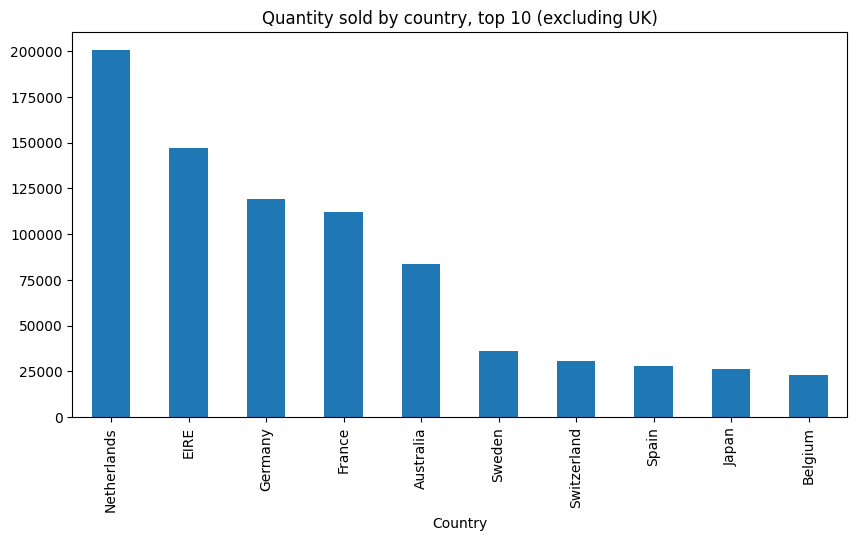

In [13]:
other = sales[sales['Country'] != 'United Kingdom']
qty = other.groupby('Country')['Quantity'].sum().sort_values(ascending=False)
print(qty.head(5))
print(qty.tail(5))
qty.head(10).plot(kind='bar', figsize=(10,5), title='Quantity sold by country, top 10 (excluding UK)');

### Question 2: Revenue by country (excluding the UK)

Country
Netherlands    285446.0
EIRE           283141.0
Germany        228678.0
France         209625.0
Australia      138454.0
Name: Total, dtype: float64
median revenue per country (GBP): 13503


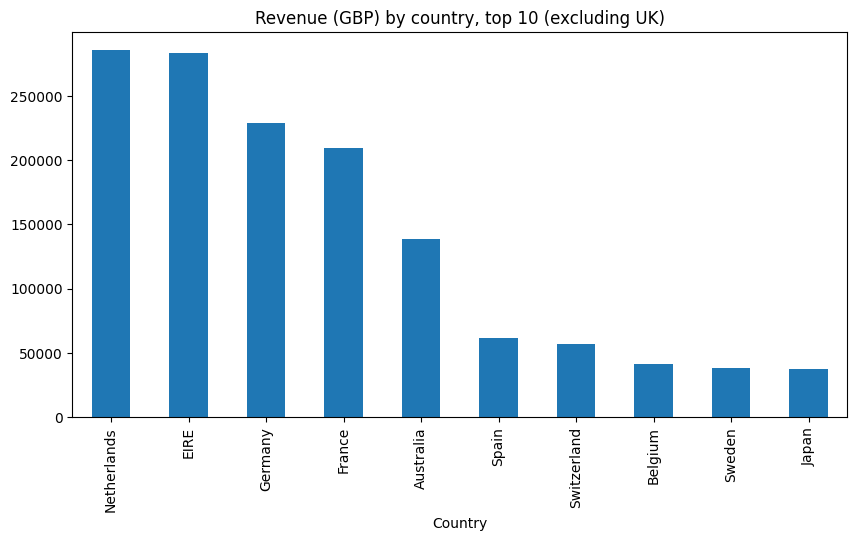

In [14]:
rev = other.groupby('Country')['Total'].sum().sort_values(ascending=False)
print(rev.head(5).round(0))
print('median revenue per country (GBP):', round(rev.median()))
rev.head(10).plot(kind='bar', figsize=(10,5), title='Revenue (GBP) by country, top 10 (excluding UK)');

### Question 3: Monthly revenue

Month
2010-12     821453.0
2011-01     689812.0
2011-02     522546.0
2011-03     716215.0
2011-04     536968.0
2011-05     769297.0
2011-06     760547.0
2011-07     718076.0
2011-08     757841.0
2011-09    1056435.0
2011-10    1151264.0
2011-11    1503867.0
2011-12     637790.0
Freq: M, Name: Total, dtype: float64


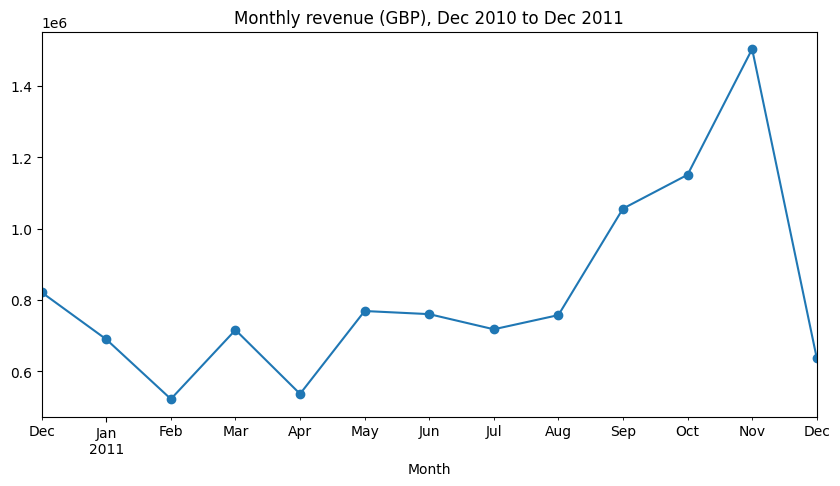

In [15]:
monthly = sales.groupby('Month')['Total'].sum()
print(monthly.round(0))
monthly.plot(kind='line', marker='o', figsize=(10,5), title='Monthly revenue (GBP), Dec 2010 to Dec 2011');

December 2011 only covers the first 9 days of the month (the data ends on 9 December 2011), so its drop is not a real decline.

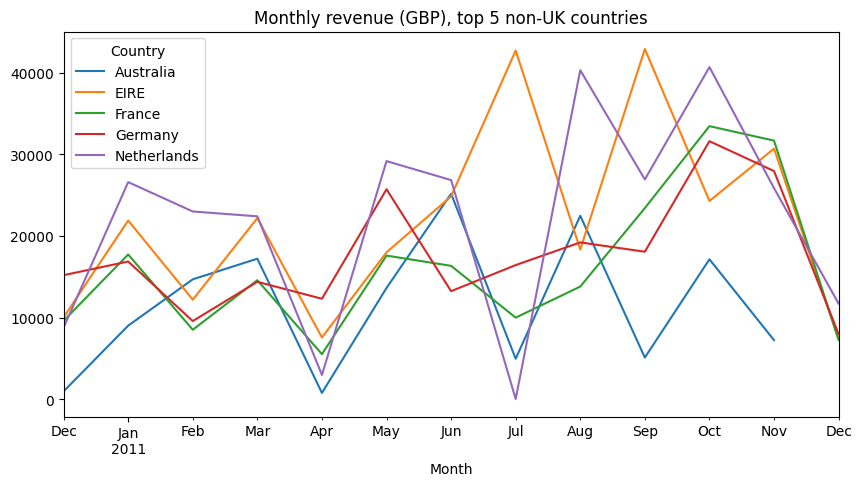

In [16]:
top_countries = rev.head(5).index
by_country = other[other['Country'].isin(top_countries)].pivot_table(index='Month', columns='Country', values='Total', aggfunc='sum')
by_country.plot(figsize=(10,5), title='Monthly revenue (GBP), top 5 non-UK countries');

### Question 4: Product revenue

In [17]:
prod = sales.groupby('StockCode').agg(Description=('Description','first'), Quantity=('Quantity','sum'), Revenue=('Total','sum'))
print(prod.sort_values('Revenue', ascending=False).head(5).round(0))
print(prod.sort_values('Revenue').head(5).round(2))

                                  Description  Quantity   Revenue
StockCode                                                        
DOT                            DOTCOM POSTAGE       706  206249.0
22423                REGENCY CAKESTAND 3 TIER     13851  174157.0
23843             PAPER CRAFT , LITTLE BIRDIE     80995  168470.0
85123A     WHITE HANGING HEART T-LIGHT HOLDER     37641  104463.0
47566                           PARTY BUNTING     18283   99445.0
                               Description  Quantity  Revenue
StockCode                                                    
PADS            PADS TO MATCH ALL CUSHIONS         3     0.00
84227            HEN HOUSE W CHICK IN NEST         1     0.42
51014c              FEATHER PEN,COAL BLACK         1     0.83
21268             VINTAGE BLUE TINSEL REEL         2     0.84
90084      PINK CRYSTAL GUITAR PHONE CHARM         1     0.85


Some stock codes are not products (for example DOT is a postage fee and POST is postage), so they are read separately from real products.

### Question 5: Quantity sold and revenue per product

Pearson: 0.66


Spearman: 0.87


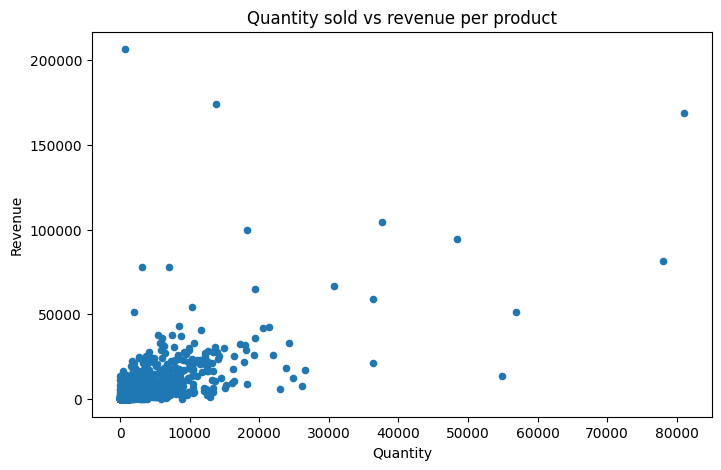

In [18]:
print('Pearson:', round(prod['Quantity'].corr(prod['Revenue']), 2))
print('Spearman:', round(prod['Quantity'].corr(prod['Revenue'], method='spearman'), 2))
prod.plot(kind='scatter', x='Quantity', y='Revenue', figsize=(8,5), title='Quantity sold vs revenue per product');

<a id='Data Visualization'></a>
## Data Visualization
A Power BI file for this project is in the repository (`Online Retail Project.pbix`). It was built before the cleaning above was corrected, so its numbers can differ from this notebook. An earlier online copy was unavailable when checked.

<a id='conclusions'></a>
## Conclusion
All amounts are in GBP.

- Question 1: Excluding the UK, the top 5 countries by quantity sold are the Netherlands, EIRE, Germany, France and Australia.
- Question 2: The same five countries lead in revenue. Excluding the UK, the median revenue of a country is about 13.5 thousand pounds, which shows how much revenue sits in a few countries (the UK alone is about 9.0 million of the 10.6 million total).
- Question 3: Revenue is flat through the first half of 2011 and climbs from September, peaking in November 2011 at about 1.5 million pounds. Each country has its own peaks, so stock planning should be done per country.
- Question 4: The highest revenue codes include DOT (postage fee) and real products such as 22423 (Regency cakestand) and 85123A (hanging heart t-light holder). Code 23843 ranks high only because of a single order of 80,995 units (invoice 581483, GBP 168,470) that was cancelled 12 minutes later in the raw data, so treat it as an outlier. Without that one order, total gross sales are GBP 10.47M instead of 10.64M (1.6% lower) and the top products are DOT, 22423, 85123A, 47566 and 85099B. The lowest are very small items and non-product codes.
- Question 5: Quantity and revenue per product are positively related (Spearman about 0.87), which is expected because price varies less than quantity. It shows association only.

### Limitations
- Revenue here is gross sales. Cancellations total about GBP 0.89M (8.4% of gross), so sales net of cancellations are about GBP 9.75M. About GBP 0.38M of the gross figure comes from non-product codes such as postage (DOT, POST), manual entries (M) and Amazon fees.
- About 25% of rows have no CustomerID, so nothing here is customer-level.
- The data covers one year (1 Dec 2010 to 9 Dec 2011), so a yearly seasonal pattern cannot be confirmed from one cycle.